In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df=pd.read_csv('/content/CarPrice_Assignment.csv')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [6]:
df.shape

(205, 26)

In [7]:
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [8]:
df.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


EDA

In [9]:
df.isnull().sum()

,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


In [10]:
df.duplicated().sum()

np.int64(0)

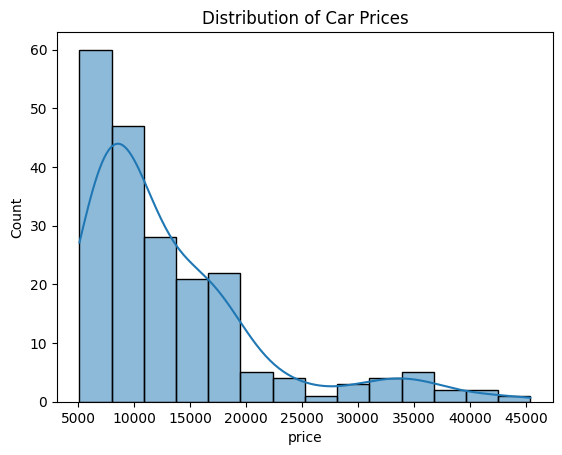

In [11]:
sns.histplot(df['price'], kde=True)
plt.title("Distribution of Car Prices")
plt.show()

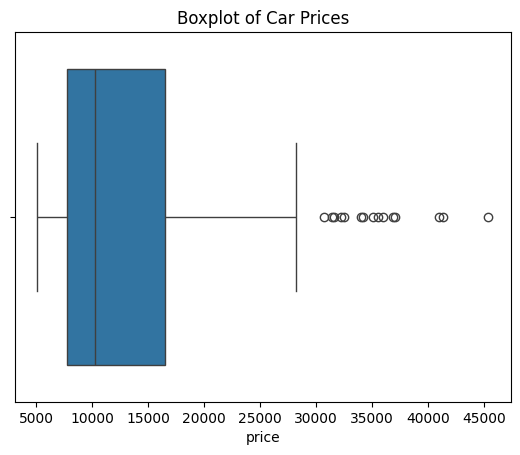

In [12]:
sns.boxplot(x=df['price'])
plt.title("Boxplot of Car Prices")
plt.show()

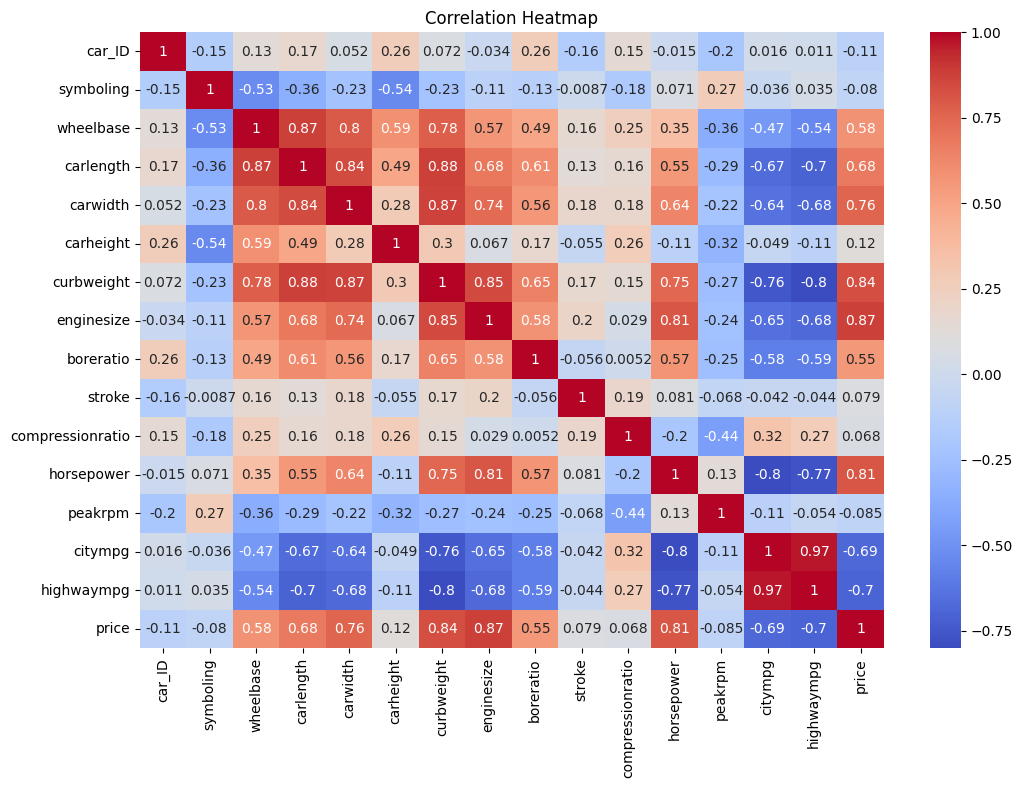

In [13]:
plt.figure(figsize=(12,8))

sns.heatmap(df.select_dtypes(include='number').corr(),
            annot=True,
            cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

In [14]:
df = df.drop(['car_ID', 'CarName'], axis=1)

In [15]:
df = pd.get_dummies(df, drop_first=True, dtype=int)

In [16]:
x = df.drop('price', axis=1)
y = df['price']

In [17]:
print(x.shape)
print(y.shape)

(205, 43)
(205,)


In [18]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [19]:
print(x_train.shape)
print(x_test.shape)

(164, 43)
(41, 43)


In [20]:
from sklearn.preprocessing import StandardScaler
SS = StandardScaler()
x_train = SS.fit_transform(x_train)
x_test = SS.transform(x_test)

Linear Regression

In [21]:
from sklearn.linear_model import LinearRegression
LR = LinearRegression()
LR.fit(x_train, y_train)

LinearRegression()

In [22]:
y_pred_LR = LR.predict(x_test)

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae= mean_absolute_error(y_test, y_pred_LR)
mse= mean_squared_error(y_test, y_pred_LR)
rmse = np.sqrt(mse)
r2= r2_score(y_test, y_pred_LR)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 2089.3827292047754
MSE: 8482008.48437192
RMSE: 2912.3887934772583
R2 Score: 0.8925566700320231


In [32]:
LR.coef_

array([ 1.20692512e+02,  6.43679737e+02, -9.89635897e+02,  1.20990838e+03,
        2.75015620e+02,  1.92582869e+03,  4.99879216e+03, -5.66775788e+02,
       -1.22804772e+03, -1.05093294e+03,  7.06006811e+01,  9.71837823e+02,
       -1.45144239e+03,  1.24548238e+03, -7.34539679e+02,  7.02935291e+02,
       -1.53576317e+02, -6.52389792e+02, -1.21330635e+03, -8.09638585e+02,
       -1.03328664e+03, -1.15846427e+02,  4.14083286e+02,  1.45017680e+03,
       -4.49992544e+02, -5.22394649e+02,  1.00005922e+03,  1.50480452e+02,
       -1.01803502e+03,  3.79046866e+00, -1.41061011e+03, -3.43568556e+03,
       -2.43044591e+03,  0.00000000e+00, -9.40750513e+02,  3.79046866e+00,
        6.98485182e+01, -7.56588787e+01,  7.34539679e+02, -2.10828847e+02,
        1.16004502e+02, -4.23533651e+02, -3.94231117e+01])

In [33]:
LR.intercept_

np.float64(13223.414634146344)

Lasso Regression

In [30]:
from sklearn.linear_model import Lasso
lasso = Lasso(alpha=1.0)
lasso.fit(x_train, y_train)
y_pred_lasso = lasso.predict(x_test)

In [31]:
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("MAE:", mae_lasso)
print("MSE:", mse_lasso)
print("RMSE:", rmse_lasso)
print("R2 Score:", r2_lasso)

MAE: 2090.172654237006
MSE: 8545794.78021207
RMSE: 2923.3191375920746
R2 Score: 0.8917486760239982


In [36]:
lasso.coef_

array([  111.32783284,   617.57365419,  -975.9089651 ,  1202.64599778,
         271.79469072,  1899.25172679,  5055.39197273,  -568.23633033,
       -1229.07965479,  -762.49097842,    70.59294481,   950.27711631,
       -1394.32618403,  1163.32552538, -1150.79207392,   714.92174662,
        -143.46189262,  -648.20212327, -1180.90148463,  -767.35891272,
       -1003.93604268,  -120.68262909,   401.90111626,  1459.33204487,
        -439.33365297,  -501.39746261,   996.76072753,   135.26675208,
       -1008.63282391,    33.8072398 , -1368.42216799, -3357.90952393,
       -2395.46121969,     0.        ,  -966.66884586,     0.        ,
          58.28174465,   -72.89254055,    12.12642021,  -208.49926967,
         105.14288632,  -411.89149281,   -42.13759564])

In [38]:
lasso.intercept_

np.float64(13223.414634146342)

Ridge Regression

In [29]:
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=1.0)
ridge.fit(x_train, y_train)
y_pred_ridge = ridge.predict(x_test)

In [39]:
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("MAE:", mae_ridge)
print("MSE:", mse_ridge)
print("RMSE:", rmse_ridge)
print("R2 Score:", r2_ridge)

MAE: 2104.3788120653785
MSE: 8998554.910634046
RMSE: 2999.759142103587
R2 Score: 0.8860134711867356


In [40]:
ridge.coef_

array([  191.58861375,   737.15278852,  -935.89104778,  1273.40458179,
         236.9276207 ,  1871.06781135,  4714.86404395,  -568.3341367 ,
       -1176.47216442,  -630.93473716,   258.66399057,   812.50075628,
        -957.25544578,   674.78140587,  -477.02483646,   615.42671927,
        -128.60903942,  -605.22856243, -1184.19768084,  -706.97615499,
        -984.61842396,  -124.55153639,   420.84082093,  1562.58394434,
        -319.67937884,  -586.91881921,   939.73370884,    77.07799178,
        -838.82922305,    90.10048844, -1113.24688432, -2736.88425764,
       -1996.50424476,     0.        ,  -878.15008947,    90.10048844,
           5.19635754,  -101.64427242,   477.02483646,  -218.31284958,
         -14.64526875,  -416.69148695,   -67.40598504])

In [41]:
ridge.intercept_

np.float64(13223.414634146344)

## **Summary**

1. To choose the best-fit model, MAE, MSE, and RMSE should be low, while the R² score should be high.
2. Among the three models, Linear Regression performed best on the test data. It achieved the lowest MAE (2089.38), MSE (8,482,008.48), and RMSE (2912.39), along with the highest R² score of 0.8926 (89.26%). Ridge and Lasso performed slightly worse.
3. Ridge Regression reduces coefficient values to control overfitting, while Lasso Regression can make some coefficients zero, removing unnecessary features. However, regularization did not improve the model's performance in this case.
4. Therefore, Linear Regression generalizes best on the given test data because it has the lowest prediction errors and highest R² score.